# Classification Track — Final (Review 2)
## 12. Consolidated 10-Algorithm Comparison, Cross-Validation & Final Model Selection

This notebook finishes the classification track. It merges the Part A results (`part_a_results.csv`, notebooks `01`–`05`)
with the Part B results (`part_b_results.csv`, notebooks `07`–`11`) into the **single consolidated comparison table
across all ten algorithms** required by the guidelines (deliverable D6, rubric A2), then:

1. ranks the models and plots the comparison,
2. runs **5-fold cross-validation** for the two best-performing models (guideline 7.2),
3. documents the **hyperparameter-tuning improvement** (baseline vs tuned) for every Part B model (rubric A3),
4. selects and justifies the **final model**, with a per-class error analysis.

Every model here was trained on the same `X_train` and scored on the same `X_test` produced by notebook `00`, so the
comparison is fair.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, os, time, warnings
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                              confusion_matrix, classification_report, roc_auc_score)
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_style("whitegrid")
sns.set_palette("colorblind")

X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze("columns")
class_map = pd.read_csv("../data/processed/class_mapping.csv", index_col=0)["class_name"].to_dict()
class_names = [class_map[i] for i in sorted(class_map.keys())]
print("X_train:", X_train.shape, " X_test:", X_test.shape)

X_train: (1688, 21)  X_test: (423, 21)


### 1. Consolidated comparison table (all 10 algorithms)

Rows come from the two result files each notebook appended to. Models are ranked by **weighted F1** (ties broken by
ROC-AUC), since F1 balances precision and recall across all seven classes.

In [2]:
part_a = pd.read_csv("../results/part_a_results.csv")
part_b = pd.read_csv("../results/part_b_results.csv")
part_a["Part"] = "A"
part_b["Part"] = "B"

final = pd.concat([part_a, part_b], ignore_index=True)
assert len(final) == 10, f"Expected 10 algorithms, found {len(final)} - re-run the missing notebooks"

final = final.sort_values(["F1_weighted", "ROC_AUC_OvR"], ascending=False).reset_index(drop=True)
final.insert(0, "Rank", final.index + 1)
final = final[["Rank", "Algorithm", "Part", "Accuracy", "Precision_weighted", "Recall_weighted",
               "F1_weighted", "ROC_AUC_OvR"]]
final.to_csv("../results/classification_final_results.csv", index=False)

final.style.format({c: "{:.4f}" for c in ["Accuracy", "Precision_weighted", "Recall_weighted",
                                          "F1_weighted", "ROC_AUC_OvR"]}) \
           .background_gradient(cmap="Greens", subset=["Accuracy", "F1_weighted", "ROC_AUC_OvR"])

,Rank,Algorithm,Part,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,ROC_AUC_OvR
0,1,Bagging (Decision Tree),B,0.9905,0.9907,0.9905,0.9905,0.9999
1,2,Random Forest,B,0.9882,0.9885,0.9882,0.9882,0.9999
2,3,AdaBoost,B,0.9882,0.9882,0.9882,0.9882,0.9992
3,4,Gradient Boosting,B,0.9835,0.9837,0.9835,0.9834,0.9998
4,5,Decision Tree,A,0.9811,0.9814,0.9811,0.9810,0.9955
5,6,Support Vector Machine (SVC),A,0.9764,0.9773,0.9764,0.9765,0.9989
6,7,MLP Classifier,B,0.9480,0.9484,0.9480,0.9481,0.9973
7,8,K-Nearest Neighbors,A,0.9243,0.9230,0.9243,0.9229,0.9864
8,9,Logistic Regression,A,0.9078,0.9088,0.9078,0.9071,0.9921
9,10,Naive Bayes (Gaussian),A,0.7447,0.7849,0.7447,0.7351,0.9497


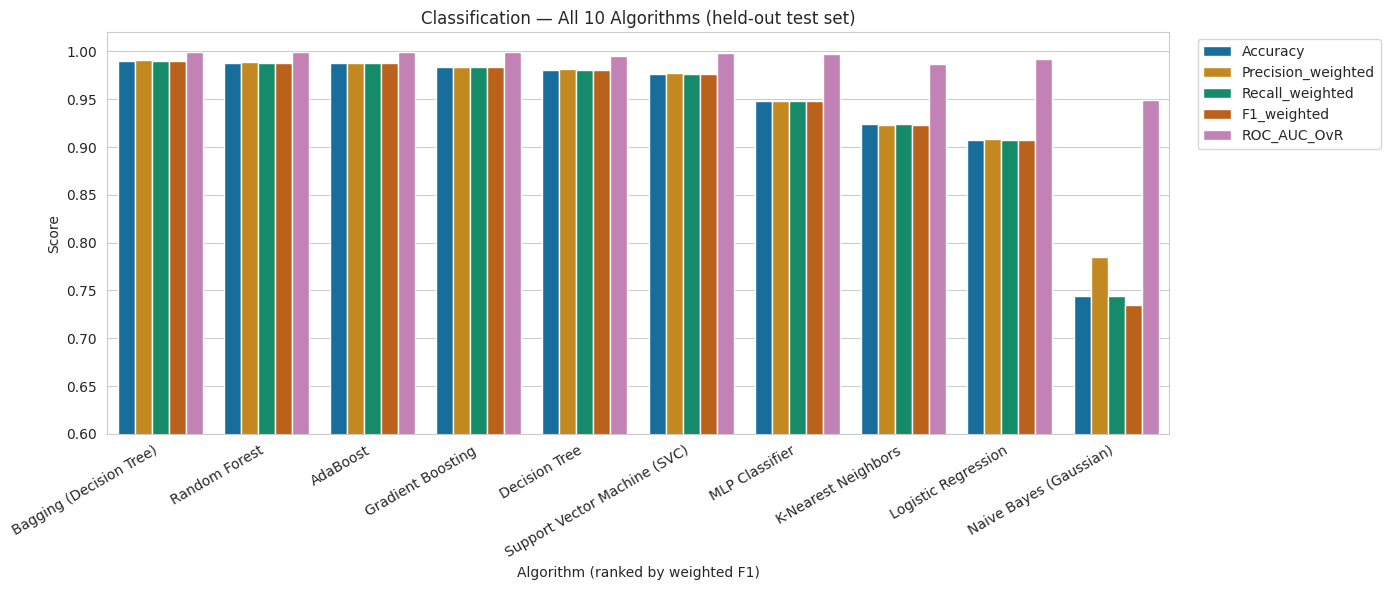

In [3]:
metrics = ["Accuracy", "Precision_weighted", "Recall_weighted", "F1_weighted", "ROC_AUC_OvR"]
melted = final.melt(id_vars="Algorithm", value_vars=metrics, var_name="Metric", value_name="Score")

fig, ax = plt.subplots(figsize=(14, 6))
sns.barplot(data=melted, x="Algorithm", y="Score", hue="Metric", order=final["Algorithm"], ax=ax)
ax.set_ylim(0.6, 1.02)
ax.set_title("Classification — All 10 Algorithms (held-out test set)")
ax.set_xlabel("Algorithm (ranked by weighted F1)")
ax.set_ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("../results/fig_final_classification_comparison.png", bbox_inches="tight")
plt.show()

### 2. Cross-validation of the two best models

A single train/test split can be lucky or unlucky, so the top two models are re-scored with **stratified 5-fold
cross-validation on the training set** (the test set stays untouched). We report the mean and standard deviation of
accuracy and weighted F1 across the folds.

Part B models are loaded from `../models/` (saved by their notebooks). Part A models weren't saved, so they are rebuilt
below with the **same tuning grids** used in notebooks `02`, `04` and `05`. This is only reached if a Part A model
ranks in the top two.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

def _tune(est, grid):
    g = GridSearchCV(est, grid, cv=5, scoring="f1_weighted", n_jobs=-1).fit(X_train, y_train)
    return g.best_estimator_

def get_estimator(name):
    """Return a fitted-hyperparameter estimator for every one of the 10 algorithms."""
    pkl = {"Random Forest": "random_forest", "AdaBoost": "adaboost", "Gradient Boosting": "gradient_boosting",
           "Bagging (Decision Tree)": "bagging", "MLP Classifier": "mlp"}
    if name in pkl:
        return joblib.load(f"../models/{pkl[name]}.pkl")
    if name == "Logistic Regression":
        return LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
    if name == "K-Nearest Neighbors":
        return _tune(KNeighborsClassifier(), {"n_neighbors": list(range(3, 22, 2)),
                                              "metric": ["euclidean", "manhattan"]})
    if name == "Naive Bayes (Gaussian)":
        return GaussianNB()
    if name == "Decision Tree":
        return _tune(DecisionTreeClassifier(random_state=RANDOM_STATE),
                     {"max_depth": list(range(2, 21, 2)), "min_samples_leaf": [1, 5, 10]})
    if name == "Support Vector Machine (SVC)":
        return _tune(SVC(random_state=RANDOM_STATE),
                     {"C": [0.1, 1, 10, 100], "kernel": ["linear", "rbf"], "gamma": ["scale"]})
    raise ValueError(name)

top2 = final["Algorithm"].head(2).tolist()
print("Top-2 models by weighted F1:", top2)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name in top2:
    est = clone(get_estimator(name))
    cv = cross_validate(est, X_train, y_train, cv=skf, scoring=["accuracy", "f1_weighted"], n_jobs=-1)
    cv_rows.append({
        "Algorithm": name,
        "CV_Accuracy_mean": cv["test_accuracy"].mean(), "CV_Accuracy_std": cv["test_accuracy"].std(),
        "CV_F1_mean": cv["test_f1_weighted"].mean(), "CV_F1_std": cv["test_f1_weighted"].std(),
    })
cv_df = pd.DataFrame(cv_rows).round(4)
cv_df.to_csv("../results/classification_top2_cv.csv", index=False)
cv_df

Top-2 models by weighted F1: ['Bagging (Decision Tree)', 'Random Forest']


,Algorithm,CV_Accuracy_mean,CV_Accuracy_std,CV_F1_mean,CV_F1_std
0,Bagging (Decision Tree),0.9805,0.0089,0.9804,0.0089
1,Random Forest,0.9864,0.0061,0.9864,0.0061


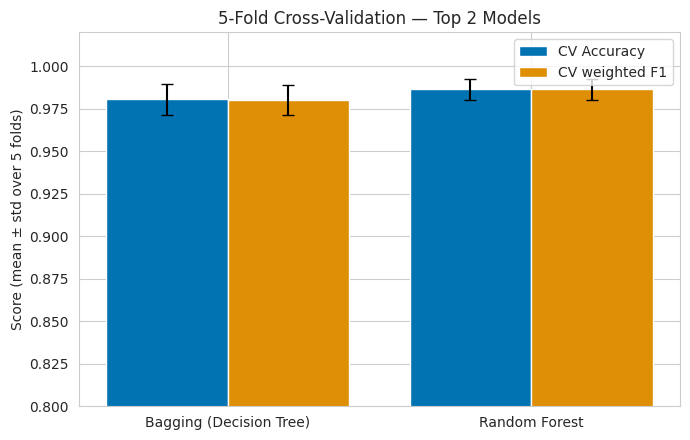

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(cv_df))
ax.bar(x - 0.2, cv_df["CV_Accuracy_mean"], 0.4, yerr=cv_df["CV_Accuracy_std"], capsize=4, label="CV Accuracy")
ax.bar(x + 0.2, cv_df["CV_F1_mean"], 0.4, yerr=cv_df["CV_F1_std"], capsize=4, label="CV weighted F1")
ax.set_xticks(x)
ax.set_xticklabels(cv_df["Algorithm"])
ax.set_ylim(0.8, 1.02)
ax.set_ylabel("Score (mean ± std over 5 folds)")
ax.set_title("5-Fold Cross-Validation — Top 2 Models")
ax.legend()
plt.tight_layout()
plt.savefig("../results/fig_top2_cross_validation.png", bbox_inches="tight")
plt.show()

### 3. Hyperparameter-tuning improvement (rubric A3)

Each Part B notebook first fitted a default-parameter baseline and then a `GridSearchCV`-tuned model, and logged both.
The table below shows what tuning actually changed on the test set. A change of zero (or a small negative) is a valid
finding — it means the defaults were already close to optimal for this dataset.

In [6]:
tuning = pd.read_csv("../results/part_b_tuning_log.csv")
tuning["F1_change"] = (tuning["Tuned_F1_weighted"] - tuning["Baseline_F1_weighted"]).round(4)
tuning["Accuracy_change"] = (tuning["Tuned_Accuracy"] - tuning["Baseline_Accuracy"]).round(4)
pd.set_option("display.max_colwidth", 120)
tuning[["Algorithm", "Baseline_F1_weighted", "Tuned_F1_weighted", "F1_change",
        "Baseline_Accuracy", "Tuned_Accuracy", "Accuracy_change", "Best_CV_F1", "Best_Params"]]

,Algorithm,Baseline_F1_weighted,Tuned_F1_weighted,F1_change,Baseline_Accuracy,Tuned_Accuracy,Accuracy_change,Best_CV_F1,Best_Params
0,Random Forest,0.9882,0.9882,0.0000,0.9882,0.9882,0.0000,0.9905,"{'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}"
1,AdaBoost,0.6318,0.9882,0.3564,0.6974,0.9882,0.2908,0.9804,"{'estimator': DecisionTreeClassifier(max_depth=3, random_state=42), 'learning_rate': 0.5, 'n_estimators': 100}"
2,Gradient Boosting,0.9834,0.9834,0.0000,0.9835,0.9835,0.0000,0.9798,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}"
3,Bagging (Decision Tree),0.9810,0.9905,0.0095,0.9811,0.9905,0.0094,0.9840,"{'max_features': 0.6, 'max_samples': 1.0, 'n_estimators': 100}"
4,MLP Classifier,0.9570,0.9481,-0.0089,0.9574,0.9480,-0.0094,0.9424,"{'activation': 'relu', 'alpha': 0.01, 'hidden_layer_sizes': (128, 64)}"


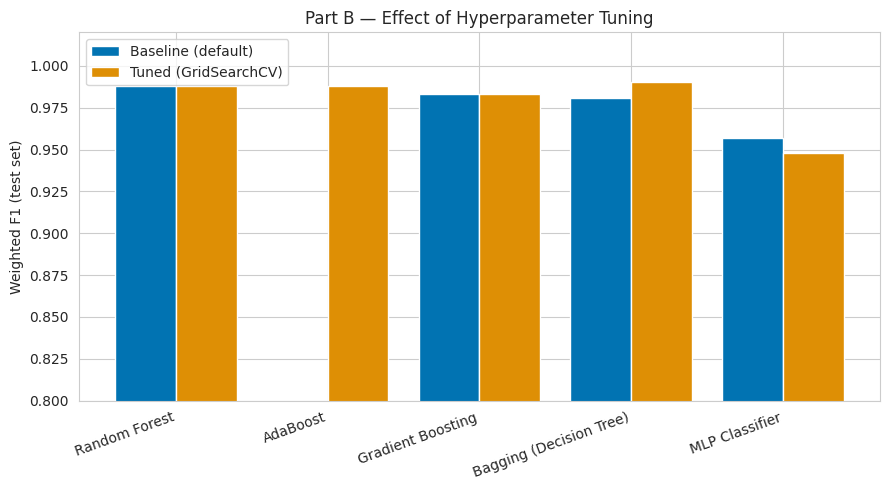

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(tuning))
ax.bar(x - 0.2, tuning["Baseline_F1_weighted"], 0.4, label="Baseline (default)")
ax.bar(x + 0.2, tuning["Tuned_F1_weighted"], 0.4, label="Tuned (GridSearchCV)")
ax.set_xticks(x)
ax.set_xticklabels(tuning["Algorithm"], rotation=20, ha="right")
ax.set_ylim(0.8, 1.02)
ax.set_ylabel("Weighted F1 (test set)")
ax.set_title("Part B — Effect of Hyperparameter Tuning")
ax.legend()
plt.tight_layout()
plt.savefig("../results/fig_part_b_tuning_effect.png", bbox_inches="tight")
plt.show()

### 4. Cost / trade-off view

Accuracy is not the only criterion. The table below adds training time (a single fit of each final estimator on the
training set) so we can discuss accuracy-vs-cost trade-offs in the viva.

In [8]:
time_rows = []
for name in final["Algorithm"]:
    est = clone(get_estimator(name))
    t0 = time.perf_counter()
    est.fit(X_train, y_train)
    time_rows.append({"Algorithm": name, "Train_time_sec": round(time.perf_counter() - t0, 3)})
time_df = pd.DataFrame(time_rows)
tradeoff = final.merge(time_df, on="Algorithm")[["Rank", "Algorithm", "F1_weighted", "ROC_AUC_OvR", "Train_time_sec"]]
tradeoff

,Rank,Algorithm,F1_weighted,ROC_AUC_OvR,Train_time_sec
0,1,Bagging (Decision Tree),0.9905,0.9999,0.360
1,2,Random Forest,0.9882,0.9999,0.229
2,3,AdaBoost,0.9882,0.9992,0.492
3,4,Gradient Boosting,0.9834,0.9998,4.700
4,5,Decision Tree,0.9810,0.9955,0.008
5,6,Support Vector Machine (SVC),0.9765,0.9989,0.084
6,7,MLP Classifier,0.9481,0.9973,0.771
7,8,K-Nearest Neighbors,0.9229,0.9864,0.002
8,9,Logistic Regression,0.9071,0.9921,0.044
9,10,Naive Bayes (Gaussian),0.7351,0.9497,0.002


### 5. Final model selection

The final model is chosen among the top two by **cross-validated weighted F1** (training data only), not by the test
score. Choosing on the test set would leak information from it into the decision, and when two models differ by only a
sample or two on a 423-row test set, that gap is noise. The test set is then used once, to report the chosen model's
performance and inspect where it still makes mistakes.

*Caveat:* the Part B hyperparameters were themselves picked with CV on the same training data, so these CV numbers are
slightly optimistic. They are still the fairer basis for comparing the two finalists.

In [9]:
best_name = cv_df.sort_values(["CV_F1_mean", "CV_F1_std"], ascending=[False, True]).iloc[0]["Algorithm"]
print("Test-set rank 1:", final.loc[0, "Algorithm"], "| CV-selected final model:", best_name)
best_model = clone(get_estimator(best_name)).fit(X_train, y_train)
y_pred = best_model.predict(X_test)
print("Final model:", best_name)
print(best_model)
print()
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

os.makedirs("../models", exist_ok=True)
joblib.dump(best_model, "../models/final_model.pkl")
print("Saved ../models/final_model.pkl")

Test-set rank 1: Bagging (Decision Tree) | CV-selected final model: Random Forest


Final model: Random Forest
RandomForestClassifier(min_samples_leaf=2, n_jobs=-1, random_state=42)

                     precision    recall  f1-score   support

Insufficient_Weight       0.98      0.98      0.98        54
      Normal_Weight       0.95      0.98      0.97        58
     Obesity_Type_I       1.00      1.00      1.00        70
    Obesity_Type_II       1.00      1.00      1.00        60
   Obesity_Type_III       1.00      1.00      1.00        65
 Overweight_Level_I       1.00      0.95      0.97        58
Overweight_Level_II       0.98      1.00      0.99        58

           accuracy                           0.99       423
          macro avg       0.99      0.99      0.99       423
       weighted avg       0.99      0.99      0.99       423

Saved ../models/final_model.pkl


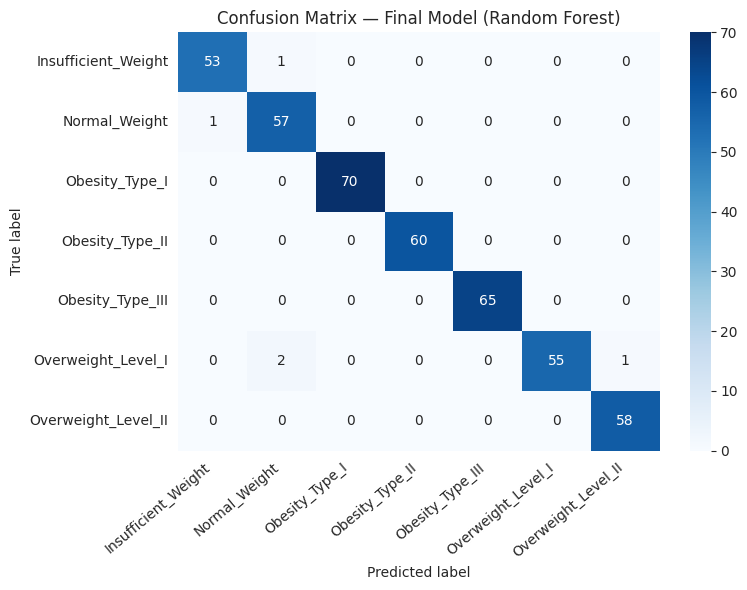

Misclassified test samples: 5 of 423
  true = Overweight_Level_I     predicted = Normal_Weight
  true = Overweight_Level_I     predicted = Normal_Weight
  true = Overweight_Level_I     predicted = Overweight_Level_II
  true = Insufficient_Weight    predicted = Normal_Weight
  true = Normal_Weight          predicted = Insufficient_Weight


In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title(f"Confusion Matrix — Final Model ({best_name})")
plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("../results/fig_confusion_matrix_final_model.png", bbox_inches="tight")
plt.show()

wrong = np.where(y_pred != y_test.values)[0]
print(f"Misclassified test samples: {len(wrong)} of {len(y_test)}")
for i in wrong:
    print(f"  true = {class_map[y_test.values[i]]:<22} predicted = {class_map[y_pred[i]]}")

### 6. Conclusion

*(Replace this cell with your own written conclusion after reading the outputs above — see the manual, section 6, for
the points to cover.)*